# Fixed-t1 four-method noise benchmark

This reader-facing copy of notebook 0003 reads the same strict 100-repeat
aggregate but excludes the abundance-only Cyclone core from every plot. The
separate applicability notebook [0004](0004_cyclone_applicability_diagnostic.ipynb)
documents why that core is not an estimator-compatible accuracy comparator for
this state-composition simulation.

Accuracy ribbons are empirical 2.5th--97.5th percentiles across repeat indices,
not confidence intervals for biological generalization. The corrected estimand
holds t1 fixed, reapplies realized-tensor lineage eligibility before every fit,
passes the same ordered clone IDs to all included methods, and uses the sole
inclusive ChronoClone post-fit cutoff `silhouette >= -0.1`.

The figures are rendered from the recorded aggregate without refitting. The two recovered-cluster-count panels use the common 0–36 axis of manuscript panels S1G–H; estimator calculations and aggregate results are unchanged.

Environment: **chronoclone**, managed by micromamba and reused without changes, at `/path/to/ChronoClone/.runtime/chronoclone`; kernel **chronoclone-paper**. Python and package versions are displayed in the setup cell.

MacBook execution command:
```bash
JUPYTER_PATH=/path/to/ChronoClone/.runtime/jupyter /path/to/ChronoClone/.runtime/chronoclone/bin/python /path/to/ChronoClone/ChronoClone_paper/benchmarks/run_notebook.py /path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/notebooks/0005_t1_locked_four_method_noise_results.ipynb --kernel chronoclone-paper
```

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import xml.etree.ElementTree as ET
import warnings
import matplotlib as mpl
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive.*")
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
NOTEBOOK_NAME = "0005_t1_locked_four_method_noise_results.ipynb"
AGGREGATE = ROOT / "results" / "aggregate"
FIGURES = ROOT / "figures" / "manuscript_four_method"
FIGURES.mkdir(parents=True, exist_ok=True)
ENVIRONMENT = {
    "manager": "micromamba",
    "name": "chronoclone",
    "historical_macbook_path": "/path/to/ChronoClone/.runtime/chronoclone",
    "current_prefix": __import__("sys").prefix,
    "kernel": "chronoclone-paper",
    "python": platform.python_version(),
    "versions": {name: importlib.metadata.version(name) for name in ["numpy", "pandas", "scipy", "scikit-learn", "scanpy", "matplotlib", "nbformat", "nbclient"]},
    "execution_command": 'JUPYTER_PATH=/path/to/ChronoClone/.runtime/jupyter /path/to/ChronoClone/.runtime/chronoclone/bin/python /path/to/ChronoClone/ChronoClone_paper/benchmarks/run_notebook.py /path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/notebooks/0005_t1_locked_four_method_noise_results.ipynb --kernel chronoclone-paper',
}
mpl.rcParams.update({"svg.fonttype": "none", "svg.hashsalt": "chronoclone-paper", "font.size": 9.5, "axes.labelsize": 9.5, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.fontsize": 8.0})
METHODS = ["ChronoClone", "CLADES preprocessing", "K-means", "Ward"]
COLORS = {"ChronoClone": "#0072B2", "CLADES preprocessing": "#D55E00", "K-means": "#CC79A7", "Ward": "#E69F00"}
ENVIRONMENT


{'manager': 'micromamba',
 'name': 'chronoclone',
 'historical_macbook_path': '/path/to/ChronoClone/.runtime/chronoclone',
 'current_prefix': '/path/to/ChronoClone/.runtime/chronoclone',
 'kernel': 'chronoclone-paper',
 'python': '3.11.15',
 'versions': {'numpy': '2.4.6',
  'pandas': '2.3.3',
  'scipy': '1.17.1',
  'scikit-learn': '1.9.0',
  'scanpy': '1.11.5',
  'matplotlib': '3.11.0',
  'nbformat': '5.10.4',
  'nbclient': '0.11.0'},
 'execution_command': 'JUPYTER_PATH=/path/to/ChronoClone/.runtime/jupyter /path/to/ChronoClone/.runtime/chronoclone/bin/python /path/to/ChronoClone/ChronoClone_paper/benchmarks/run_notebook.py /path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/notebooks/0005_t1_locked_four_method_noise_results.ipynb --kernel chronoclone-paper'}

In [2]:
def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

metadata = json.loads((AGGREGATE / "aggregation_metadata.json").read_text())
assert metadata["status"] == "pass"
for artifact_name, expected in metadata["artifact_sha256"].items():
    assert sha256(AGGREGATE / artifact_name) == expected
for artifact_name, record in metadata.get("omitted_large_artifacts", {}).items():
    assert len(record["sha256"]) == 64 and record["bytes"] > 100_000_000
summary = pd.read_csv(AGGREGATE / "native_method_noise_summary.csv")
completeness = pd.read_csv(AGGREGATE / "result_completeness.csv")
eligibility = pd.read_csv(AGGREGATE / "eligibility_summary.csv")
selective = pd.read_csv(AGGREGATE / "chronoclone_selective_summary.csv")
same_retained = pd.read_csv(AGGREGATE / "same_retained_subset_summary.csv")
failures = pd.read_csv(AGGREGATE / "method_failure_counts.csv")
assert len(summary) == len(completeness) == len(same_retained) == 5 * 51 * 51
assert len(eligibility) == len(selective) == 51 * 51
assert not summary.duplicated(["method", "gaussian_pct", "uniform_pct"]).any()
assert not eligibility.duplicated(["gaussian_pct", "uniform_pct"]).any()
assert (completeness["n_expected"] == 100).all()
assert (completeness["n_success"] + completeness["n_method_failure"] == 100).all()

# The aggregate remains the complete five-method source. Reader-facing tables
# and plots below use only the four estimator-compatible methods requested here.
summary_plot = summary.loc[summary["method"].isin(METHODS)].copy()
completeness_plot = completeness.loc[completeness["method"].isin(METHODS)].copy()
same_retained_plot = same_retained.loc[same_retained["method"].isin(METHODS)].copy()
failures_plot = failures.loc[failures["method"].isin(METHODS)].copy()
assert set(summary_plot["method"]) == set(METHODS)
assert len(summary_plot) == len(completeness_plot) == len(same_retained_plot) == 4 * 51 * 51
assert completeness_plot["n_success"].eq(100).all()
assert completeness_plot["n_method_failure"].eq(0).all()
assert failures_plot.empty

metadata_display = dict(metadata)
metadata_display["t1_lock_validated"] = metadata_display.get("t1_lock_validated", metadata_display.get("day0_lock_validated"))
metadata_display.pop("day0_lock_validated", None)
metadata_display.pop("schema", None)
metadata_display.pop("method_failure_rows", None)
metadata_display["plotted_methods"] = ", ".join(METHODS)
metadata_display["plotted_method_failure_rows"] = int(completeness_plot["n_method_failure"].sum())
display(pd.DataFrame([metadata_display]).T.rename(columns={0: "value"}))
display(completeness_plot.groupby("method", sort=False)[["n_expected", "n_success", "n_method_failure"]].sum())

,value
aggregation_completed_at_utc,2026-08-13T20:48:04.342186+00:00
artifact_sha256,{'chronoclone_selective_summary.csv': '612d549...
chronoclone_selective_summary_rows,2601
cyclone_uniform_invariance_validated,True
deterministic_clean_baseline_validated,True
eligibility_summary_rows,2601
expected_chunks,600
expected_rows,1300500
five_method_common_cohort_validated,True
hash_contract,{'chronoclone_package_tree_sha256': '3a5bbeb6a...


,n_expected,n_success,n_method_failure
method,,,
ChronoClone,260100,260100,0
CLADES preprocessing,260100,260100,0
K-means,260100,260100,0
Ward,260100,260100,0


## Full-cohort accuracy

The two axis plots isolate one noise mechanism. Each of the four included
method heatmaps then shows the complete Gaussian-then-uniform grid on a common
0--1 ARI scale.

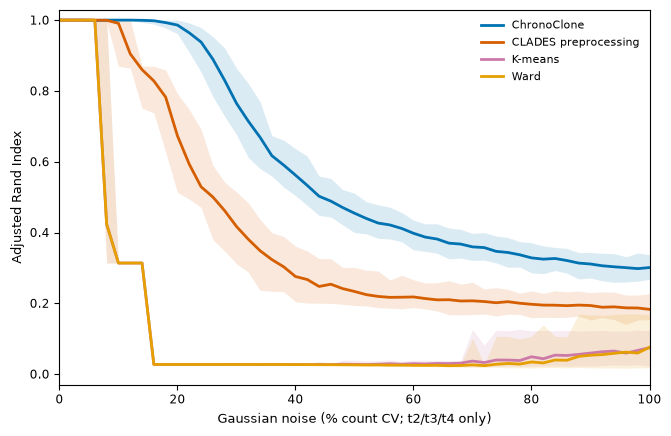

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/manuscript_four_method/gaussian_only_mean_ari_by_method.svg


In [3]:
# Plot-specific shaping and full construction: Gaussian noise only mean ARI
axis_data = summary_plot.loc[summary["uniform_pct"].eq(0)].copy()
fig, ax = plt.subplots(figsize=(6.8, 4.45))
for method in METHODS:
    data = axis_data.loc[axis_data["method"].eq(method)].sort_values('gaussian_pct')
    x = data['gaussian_pct'].to_numpy(float)
    mean = data["ari_mean"].to_numpy(float)
    lower = data["ari_q025"].to_numpy(float)
    upper = data["ari_q975"].to_numpy(float)
    finite = np.isfinite(mean)
    if finite.any():
        ax.plot(x[finite], mean[finite], color=COLORS[method], linewidth=2.0, label=method)
        band = finite & np.isfinite(lower) & np.isfinite(upper)
        if band.any():
            ax.fill_between(x[band], lower[band], upper[band], color=COLORS[method], alpha=0.14, linewidth=0)
ax.set_xlim(0, 100)
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel('Gaussian noise (% count CV; t2/t3/t4 only)')
ax.set_ylabel("Adjusted Rand Index")
handles, labels = ax.get_legend_handles_labels()
if handles:
    ax.legend(handles, labels, frameon=False, fontsize=8)
fig.tight_layout()
output_path = FIGURES / 'gaussian_only_mean_ari_by_method.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
fig.savefig(output_path.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()
print(output_path)


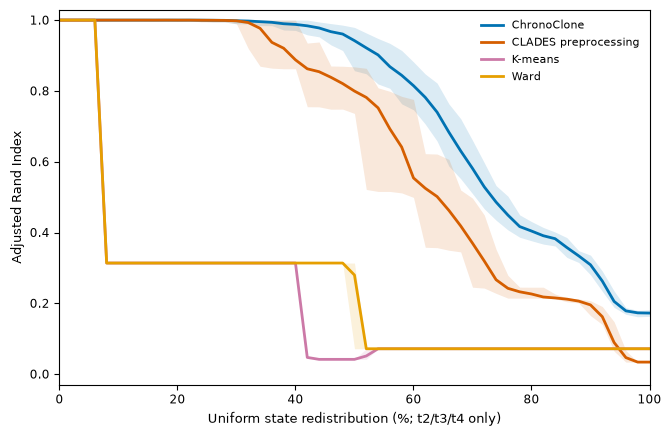

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/manuscript_four_method/uniform_only_mean_ari_by_method.svg


In [4]:
# Plot-specific shaping and full construction: Uniform redistribution only mean ARI
axis_data = summary_plot.loc[summary["gaussian_pct"].eq(0)].copy()
fig, ax = plt.subplots(figsize=(6.8, 4.45))
for method in METHODS:
    data = axis_data.loc[axis_data["method"].eq(method)].sort_values('uniform_pct')
    x = data['uniform_pct'].to_numpy(float)
    mean = data["ari_mean"].to_numpy(float)
    lower = data["ari_q025"].to_numpy(float)
    upper = data["ari_q975"].to_numpy(float)
    finite = np.isfinite(mean)
    if finite.any():
        ax.plot(x[finite], mean[finite], color=COLORS[method], linewidth=2.0, label=method)
        band = finite & np.isfinite(lower) & np.isfinite(upper)
        if band.any():
            ax.fill_between(x[band], lower[band], upper[band], color=COLORS[method], alpha=0.14, linewidth=0)
ax.set_xlim(0, 100)
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel('Uniform state redistribution (%; t2/t3/t4 only)')
ax.set_ylabel("Adjusted Rand Index")
handles, labels = ax.get_legend_handles_labels()
if handles:
    ax.legend(handles, labels, frameon=False, fontsize=8)
fig.tight_layout()
output_path = FIGURES / 'uniform_only_mean_ari_by_method.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
fig.savefig(output_path.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()
print(output_path)


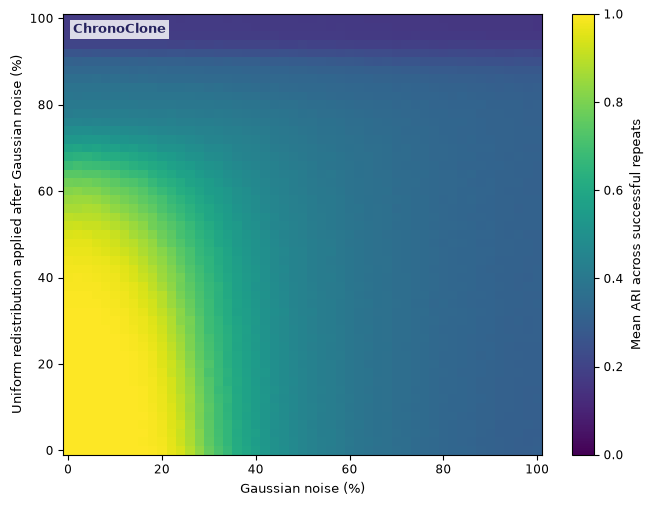

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/manuscript_four_method/chronoclone_mean_ari_heatmap.svg


In [5]:
# Plot-specific shaping and full construction: ChronoClone mean-ARI heatmap
heat_source = summary_plot.loc[summary["method"].eq('ChronoClone'), ["gaussian_pct", "uniform_pct", "ari_mean"]].copy()
heat = heat_source.pivot(index="uniform_pct", columns="gaussian_pct", values="ari_mean").sort_index().sort_index(axis=1)
assert heat.shape == (51, 51)
x = heat.columns.to_numpy(float)
y = heat.index.to_numpy(float)
x_edges = np.r_[x - 1.0, x[-1] + 1.0]
y_edges = np.r_[y - 1.0, y[-1] + 1.0]
values = np.ma.masked_invalid(heat.to_numpy(float))
fig, ax = plt.subplots(figsize=(6.8, 5.15))
ax.set_facecolor("#EEEEEE")
mesh = ax.pcolormesh(x_edges, y_edges, values, shading="flat", vmin=0, vmax=1, cmap="viridis")
if values.count() == 0:
    ax.text(50, 50, "No successful fits", ha="center", va="center", fontsize=12, color="#555555")
ax.set_xlim(-1, 101)
ax.set_ylim(-1, 101)
ax.set_xticks(np.arange(0, 101, 20))
ax.set_yticks(np.arange(0, 101, 20))
ax.set_xlabel("Gaussian noise (%)")
ax.set_ylabel("Uniform redistribution applied after Gaussian noise (%)")
ax.text(0.02, 0.98, 'ChronoClone', transform=ax.transAxes, ha="left", va="top", fontsize=9.5, fontweight="bold", color="#26235F", bbox=dict(facecolor="white", edgecolor="none", alpha=0.82, pad=2.0))
colorbar = fig.colorbar(mesh, ax=ax)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Mean ARI across successful repeats")
fig.tight_layout()
output_path = FIGURES / 'chronoclone_mean_ari_heatmap.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
fig.savefig(output_path.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()
print(output_path)


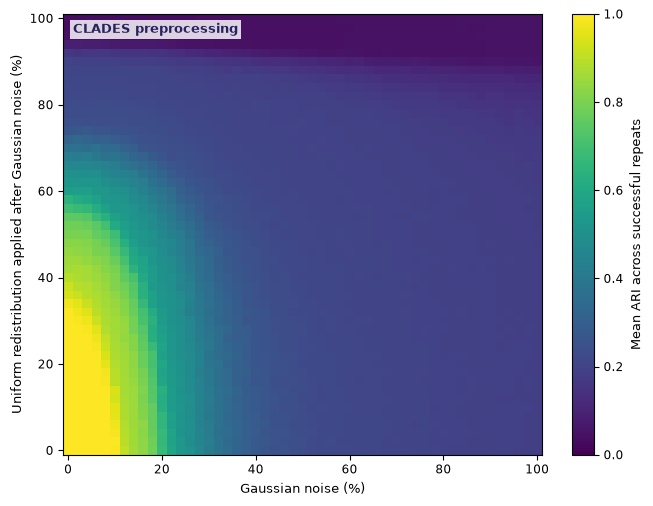

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/manuscript_four_method/clades_preprocessing_mean_ari_heatmap.svg


In [6]:
# Plot-specific shaping and full construction: CLADES preprocessing mean-ARI heatmap
heat_source = summary_plot.loc[summary["method"].eq('CLADES preprocessing'), ["gaussian_pct", "uniform_pct", "ari_mean"]].copy()
heat = heat_source.pivot(index="uniform_pct", columns="gaussian_pct", values="ari_mean").sort_index().sort_index(axis=1)
assert heat.shape == (51, 51)
x = heat.columns.to_numpy(float)
y = heat.index.to_numpy(float)
x_edges = np.r_[x - 1.0, x[-1] + 1.0]
y_edges = np.r_[y - 1.0, y[-1] + 1.0]
values = np.ma.masked_invalid(heat.to_numpy(float))
fig, ax = plt.subplots(figsize=(6.8, 5.15))
ax.set_facecolor("#EEEEEE")
mesh = ax.pcolormesh(x_edges, y_edges, values, shading="flat", vmin=0, vmax=1, cmap="viridis")
if values.count() == 0:
    ax.text(50, 50, "No successful fits", ha="center", va="center", fontsize=12, color="#555555")
ax.set_xlim(-1, 101)
ax.set_ylim(-1, 101)
ax.set_xticks(np.arange(0, 101, 20))
ax.set_yticks(np.arange(0, 101, 20))
ax.set_xlabel("Gaussian noise (%)")
ax.set_ylabel("Uniform redistribution applied after Gaussian noise (%)")
ax.text(0.02, 0.98, 'CLADES preprocessing', transform=ax.transAxes, ha="left", va="top", fontsize=9.5, fontweight="bold", color="#26235F", bbox=dict(facecolor="white", edgecolor="none", alpha=0.82, pad=2.0))
colorbar = fig.colorbar(mesh, ax=ax)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Mean ARI across successful repeats")
fig.tight_layout()
output_path = FIGURES / 'clades_preprocessing_mean_ari_heatmap.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
fig.savefig(output_path.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()
print(output_path)


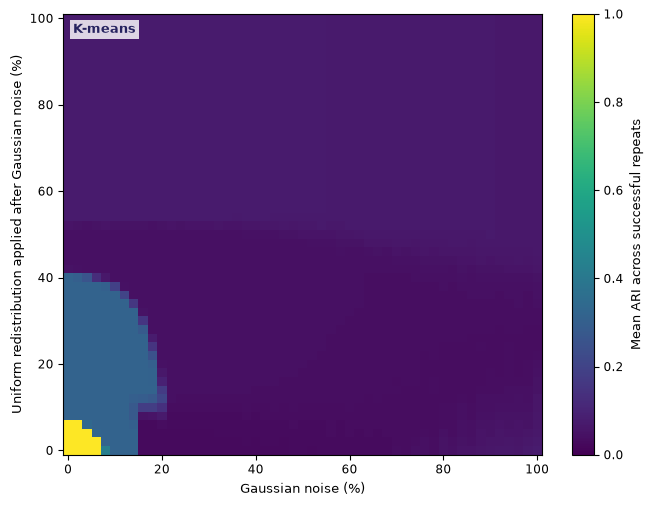

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/manuscript_four_method/kmeans_mean_ari_heatmap.svg


In [7]:
# Plot-specific shaping and full construction: K-means mean-ARI heatmap
heat_source = summary_plot.loc[summary["method"].eq('K-means'), ["gaussian_pct", "uniform_pct", "ari_mean"]].copy()
heat = heat_source.pivot(index="uniform_pct", columns="gaussian_pct", values="ari_mean").sort_index().sort_index(axis=1)
assert heat.shape == (51, 51)
x = heat.columns.to_numpy(float)
y = heat.index.to_numpy(float)
x_edges = np.r_[x - 1.0, x[-1] + 1.0]
y_edges = np.r_[y - 1.0, y[-1] + 1.0]
values = np.ma.masked_invalid(heat.to_numpy(float))
fig, ax = plt.subplots(figsize=(6.8, 5.15))
ax.set_facecolor("#EEEEEE")
mesh = ax.pcolormesh(x_edges, y_edges, values, shading="flat", vmin=0, vmax=1, cmap="viridis")
if values.count() == 0:
    ax.text(50, 50, "No successful fits", ha="center", va="center", fontsize=12, color="#555555")
ax.set_xlim(-1, 101)
ax.set_ylim(-1, 101)
ax.set_xticks(np.arange(0, 101, 20))
ax.set_yticks(np.arange(0, 101, 20))
ax.set_xlabel("Gaussian noise (%)")
ax.set_ylabel("Uniform redistribution applied after Gaussian noise (%)")
ax.text(0.02, 0.98, 'K-means', transform=ax.transAxes, ha="left", va="top", fontsize=9.5, fontweight="bold", color="#26235F", bbox=dict(facecolor="white", edgecolor="none", alpha=0.82, pad=2.0))
colorbar = fig.colorbar(mesh, ax=ax)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Mean ARI across successful repeats")
fig.tight_layout()
output_path = FIGURES / 'kmeans_mean_ari_heatmap.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
fig.savefig(output_path.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()
print(output_path)


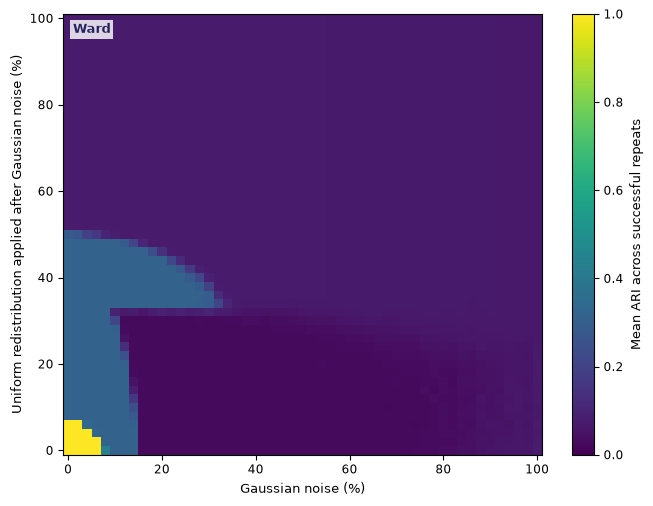

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/manuscript_four_method/ward_mean_ari_heatmap.svg


In [8]:
# Plot-specific shaping and full construction: Ward mean-ARI heatmap
heat_source = summary_plot.loc[summary["method"].eq('Ward'), ["gaussian_pct", "uniform_pct", "ari_mean"]].copy()
heat = heat_source.pivot(index="uniform_pct", columns="gaussian_pct", values="ari_mean").sort_index().sort_index(axis=1)
assert heat.shape == (51, 51)
x = heat.columns.to_numpy(float)
y = heat.index.to_numpy(float)
x_edges = np.r_[x - 1.0, x[-1] + 1.0]
y_edges = np.r_[y - 1.0, y[-1] + 1.0]
values = np.ma.masked_invalid(heat.to_numpy(float))
fig, ax = plt.subplots(figsize=(6.8, 5.15))
ax.set_facecolor("#EEEEEE")
mesh = ax.pcolormesh(x_edges, y_edges, values, shading="flat", vmin=0, vmax=1, cmap="viridis")
if values.count() == 0:
    ax.text(50, 50, "No successful fits", ha="center", va="center", fontsize=12, color="#555555")
ax.set_xlim(-1, 101)
ax.set_ylim(-1, 101)
ax.set_xticks(np.arange(0, 101, 20))
ax.set_yticks(np.arange(0, 101, 20))
ax.set_xlabel("Gaussian noise (%)")
ax.set_ylabel("Uniform redistribution applied after Gaussian noise (%)")
ax.text(0.02, 0.98, 'Ward', transform=ax.transAxes, ha="left", va="top", fontsize=9.5, fontweight="bold", color="#26235F", bbox=dict(facecolor="white", edgecolor="none", alpha=0.82, pad=2.0))
colorbar = fig.colorbar(mesh, ax=ax)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Mean ARI across successful repeats")
fig.tight_layout()
output_path = FIGURES / 'ward_mean_ari_heatmap.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
fig.savefig(output_path.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()
print(output_path)


## Applicability, eligibility, and native selection

All four plotted methods return a finite native partition in every requested
condition. The success plots therefore show their shared 100% fit fraction as
one neutral curve rather than four perfectly overlapping method lines.
Recovered K remains descriptive of each truth-blind native selector. Selection
parameters are not numerically comparable across methods, so their values are
tabulated rather than placed on one scale.

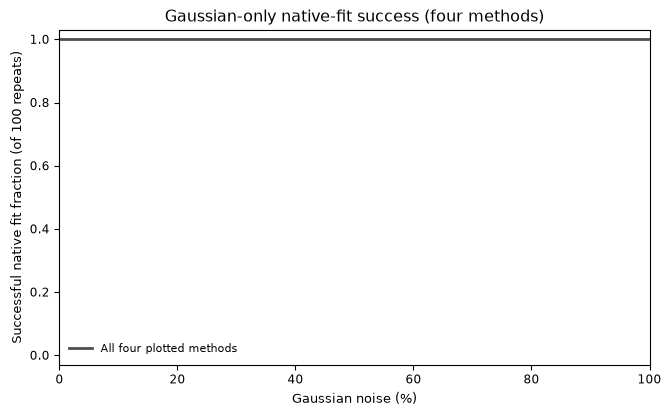

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/manuscript_four_method/gaussian_only_method_success_fraction.svg


In [9]:
# Plot-specific shaping and full construction: Gaussian-only native-fit success (four methods)
success_axis = completeness_plot.loc[completeness_plot["uniform_pct"].eq(0)].copy()
assert set(success_axis["method"]) == set(METHODS)
assert success_axis["success_fraction"].eq(1.0).all()
success_by_noise = (
    success_axis.groupby('gaussian_pct', as_index=False)
    .agg(
        minimum_success_fraction=("success_fraction", "min"),
        maximum_success_fraction=("success_fraction", "max"),
    )
    .sort_values('gaussian_pct')
)
assert np.allclose(
    success_by_noise["minimum_success_fraction"],
    success_by_noise["maximum_success_fraction"],
)
x = success_by_noise['gaussian_pct'].to_numpy(float)
y = success_by_noise["minimum_success_fraction"].to_numpy(float)
fig, ax = plt.subplots(figsize=(6.8, 4.25))
ax.plot(x, y, color="#4D4D4D", linewidth=2.0, label="All four plotted methods")
ax.set_xlim(0, 100)
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel('Gaussian noise (%)')
ax.set_ylabel("Successful native fit fraction (of 100 repeats)")
ax.set_title('Gaussian-only native-fit success (four methods)')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
output_path = FIGURES / 'gaussian_only_method_success_fraction.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
fig.savefig(output_path.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()
print(output_path)

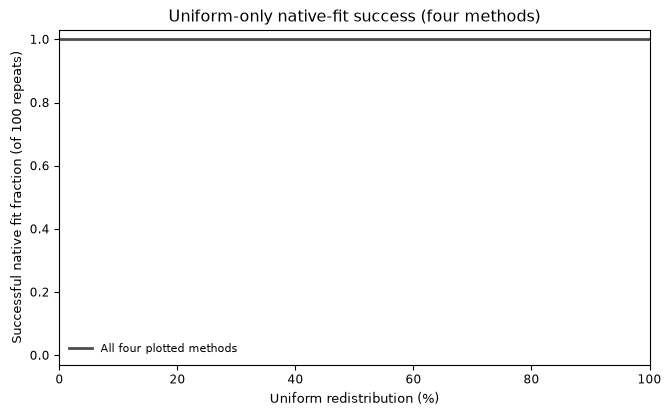

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/manuscript_four_method/uniform_only_method_success_fraction.svg


In [10]:
# Plot-specific shaping and full construction: Uniform-only native-fit success (four methods)
success_axis = completeness_plot.loc[completeness_plot["gaussian_pct"].eq(0)].copy()
assert set(success_axis["method"]) == set(METHODS)
assert success_axis["success_fraction"].eq(1.0).all()
success_by_noise = (
    success_axis.groupby('uniform_pct', as_index=False)
    .agg(
        minimum_success_fraction=("success_fraction", "min"),
        maximum_success_fraction=("success_fraction", "max"),
    )
    .sort_values('uniform_pct')
)
assert np.allclose(
    success_by_noise["minimum_success_fraction"],
    success_by_noise["maximum_success_fraction"],
)
x = success_by_noise['uniform_pct'].to_numpy(float)
y = success_by_noise["minimum_success_fraction"].to_numpy(float)
fig, ax = plt.subplots(figsize=(6.8, 4.25))
ax.plot(x, y, color="#4D4D4D", linewidth=2.0, label="All four plotted methods")
ax.set_xlim(0, 100)
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel('Uniform redistribution (%)')
ax.set_ylabel("Successful native fit fraction (of 100 repeats)")
ax.set_title('Uniform-only native-fit success (four methods)')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
output_path = FIGURES / 'uniform_only_method_success_fraction.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
fig.savefig(output_path.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()
print(output_path)

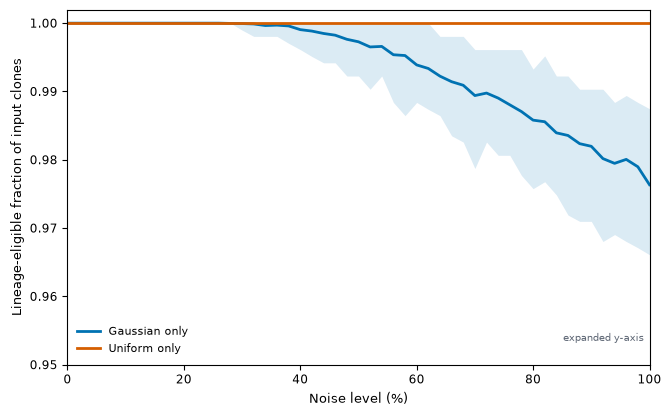

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/manuscript_four_method/isolated_axes_eligible_clone_fraction.svg


In [11]:
# Plot-specific shaping and full construction: common eligibility on both isolated axes
gaussian_eligibility = eligibility.loc[eligibility["uniform_pct"].eq(0)].sort_values("gaussian_pct").copy()
uniform_eligibility = eligibility.loc[eligibility["gaussian_pct"].eq(0)].sort_values("uniform_pct").copy()
fig, ax = plt.subplots(figsize=(6.8, 4.25))
for label, data, x_column, color in [
    ("Gaussian only", gaussian_eligibility, "gaussian_pct", "#0072B2"),
    ("Uniform only", uniform_eligibility, "uniform_pct", "#D55E00"),
]:
    x = data[x_column].to_numpy(float)
    mean = data["eligible_fraction_mean"].to_numpy(float)
    lower = data["eligible_fraction_q025"].to_numpy(float)
    upper = data["eligible_fraction_q975"].to_numpy(float)
    ax.plot(x, mean, color=color, linewidth=2.0, label=label)
    ax.fill_between(x, lower, upper, color=color, alpha=0.14, linewidth=0)
ax.set_xlim(0, 100)
ax.set_ylim(0.95, 1.002)
ax.set_yticks(np.arange(0.95, 1.001, 0.01))
ax.text(0.99, 0.06, 'expanded y-axis', transform=ax.transAxes, ha='right', va='bottom', fontsize=7.5, color='#5B6472')
ax.set_xlabel("Noise level (%)")
ax.set_ylabel("Lineage-eligible fraction of input clones")
ax.legend(frameon=False)
fig.tight_layout()
output_path = FIGURES / "isolated_axes_eligible_clone_fraction.svg"
fig.savefig(output_path, format="svg", bbox_inches="tight")
fig.savefig(output_path.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()
print(output_path)


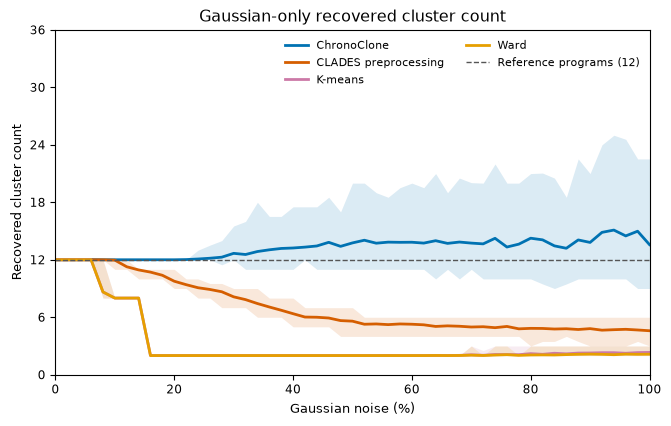

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/manuscript_four_method/gaussian_only_recovered_k.svg


In [12]:
# Plot-specific shaping and full construction: Gaussian-only recovered cluster count
k_axis = summary_plot.loc[summary["uniform_pct"].eq(0)].copy()
fig, ax = plt.subplots(figsize=(6.8, 4.35))
for method in METHODS:
    data = k_axis.loc[k_axis["method"].eq(method)].sort_values('gaussian_pct')
    x = data['gaussian_pct'].to_numpy(float)
    mean = data["recovered_k_mean"].to_numpy(float)
    lower = data["recovered_k_q025"].to_numpy(float)
    upper = data["recovered_k_q975"].to_numpy(float)
    finite = np.isfinite(mean)
    if finite.any():
        ax.plot(x[finite], mean[finite], color=COLORS[method], linewidth=2.0, label=method)
        band = finite & np.isfinite(lower) & np.isfinite(upper)
        if band.any():
            ax.fill_between(x[band], lower[band], upper[band], color=COLORS[method], alpha=0.14, linewidth=0)
ax.axhline(12, color="#555555", linewidth=1, linestyle="--", label="Reference programs (12)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 36)
ax.set_yticks(np.arange(0, 37, 6))
ax.set_xlabel('Gaussian noise (%)')
ax.set_ylabel("Recovered cluster count")
ax.set_title('Gaussian-only recovered cluster count')
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
output_path = FIGURES / 'gaussian_only_recovered_k.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
fig.savefig(output_path.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()
print(output_path)


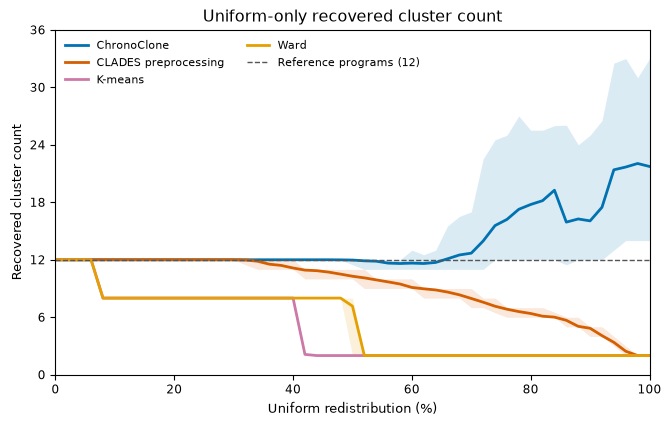

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/manuscript_four_method/uniform_only_recovered_k.svg


In [13]:
# Plot-specific shaping and full construction: Uniform-only recovered cluster count
k_axis = summary_plot.loc[summary["gaussian_pct"].eq(0)].copy()
fig, ax = plt.subplots(figsize=(6.8, 4.35))
for method in METHODS:
    data = k_axis.loc[k_axis["method"].eq(method)].sort_values('uniform_pct')
    x = data['uniform_pct'].to_numpy(float)
    mean = data["recovered_k_mean"].to_numpy(float)
    lower = data["recovered_k_q025"].to_numpy(float)
    upper = data["recovered_k_q975"].to_numpy(float)
    finite = np.isfinite(mean)
    if finite.any():
        ax.plot(x[finite], mean[finite], color=COLORS[method], linewidth=2.0, label=method)
        band = finite & np.isfinite(lower) & np.isfinite(upper)
        if band.any():
            ax.fill_between(x[band], lower[band], upper[band], color=COLORS[method], alpha=0.14, linewidth=0)
ax.axhline(12, color="#555555", linewidth=1, linestyle="--", label="Reference programs (12)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 36)
ax.set_yticks(np.arange(0, 37, 6))
ax.set_xlabel('Uniform redistribution (%)')
ax.set_ylabel("Recovered cluster count")
ax.set_title('Uniform-only recovered cluster count')
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
output_path = FIGURES / 'uniform_only_recovered_k.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
fig.savefig(output_path.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()
print(output_path)


In [14]:
selector_axes = pd.concat(
    [
        summary_plot.loc[summary["uniform_pct"].eq(0), ["method", "gaussian_pct", "selection_parameter_mean", "selected_silhouette_mean", "recovered_k_mean"]].assign(axis="Gaussian only", noise_pct=lambda x: x["gaussian_pct"]),
        summary_plot.loc[summary["gaussian_pct"].eq(0), ["method", "uniform_pct", "selection_parameter_mean", "selected_silhouette_mean", "recovered_k_mean"]].assign(axis="Uniform only", noise_pct=lambda x: x["uniform_pct"]),
    ],
    ignore_index=True,
)
selector_endpoints = selector_axes.loc[selector_axes["noise_pct"].isin([0, 10, 20, 50, 100]), ["axis", "noise_pct", "method", "selection_parameter_mean", "selected_silhouette_mean", "recovered_k_mean"]]
display(selector_endpoints.sort_values(["axis", "noise_pct", "method"]))


,axis,noise_pct,method,selection_parameter_mean,selected_silhouette_mean,recovered_k_mean
51,Gaussian only,0,CLADES preprocessing,0.2500,NaN,12.00
0,Gaussian only,0,ChronoClone,0.0100,1.000000,12.00
102,Gaussian only,0,K-means,12.0000,1.000000,12.00
153,Gaussian only,0,Ward,12.0000,1.000000,12.00
56,Gaussian only,10,CLADES preprocessing,0.2500,NaN,11.96
5,Gaussian only,10,ChronoClone,0.6292,0.701734,12.00
107,Gaussian only,10,K-means,8.0000,0.742205,8.00
158,Gaussian only,10,Ward,8.0000,0.742205,8.00
61,Gaussian only,20,CLADES preprocessing,0.2500,NaN,9.76
10,Gaussian only,20,ChronoClone,0.6768,0.494604,12.00


## ChronoClone selection and common retained-set sensitivity

ChronoClone conditional accuracy is paired with retained-clone coverage. For
the sensitivity curves, every already-fitted comparator is rescored on the
same ChronoClone-retained IDs without refitting. The plotted difference is a
within-method denominator sensitivity, not a filtered-ChronoClone superiority
contrast.


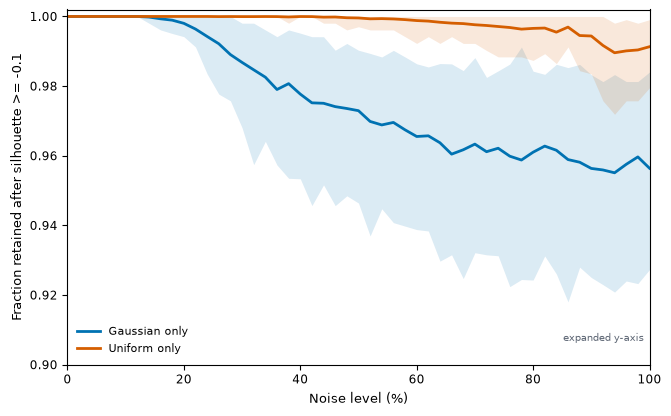

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/manuscript_four_method/chronoclone_isolated_axes_postfit_coverage.svg


In [15]:
# Plot-specific shaping and full construction: ChronoClone post-fit coverage
gaussian_coverage = selective.loc[selective["uniform_pct"].eq(0)].sort_values("gaussian_pct").copy()
uniform_coverage = selective.loc[selective["gaussian_pct"].eq(0)].sort_values("uniform_pct").copy()
fig, ax = plt.subplots(figsize=(6.8, 4.25))
for label, data, x_column, color in [
    ("Gaussian only", gaussian_coverage, "gaussian_pct", "#0072B2"),
    ("Uniform only", uniform_coverage, "uniform_pct", "#D55E00"),
]:
    x = data[x_column].to_numpy(float)
    mean = data["postfit_retained_fraction_of_eligible_mean"].to_numpy(float)
    lower = data["postfit_retained_fraction_of_eligible_q025"].to_numpy(float)
    upper = data["postfit_retained_fraction_of_eligible_q975"].to_numpy(float)
    ax.plot(x, mean, color=color, linewidth=2.0, label=label)
    ax.fill_between(x, lower, upper, color=color, alpha=0.14, linewidth=0)
ax.set_xlim(0, 100)
ax.set_ylim(0.90, 1.002)
ax.set_yticks(np.arange(0.90, 1.001, 0.02))
ax.text(0.99, 0.06, 'expanded y-axis', transform=ax.transAxes, ha='right', va='bottom', fontsize=7.5, color='#5B6472')
ax.set_xlabel("Noise level (%)")
ax.set_ylabel("Fraction retained after silhouette >= -0.1")
ax.legend(frameon=False)
fig.tight_layout()
output_path = FIGURES / "chronoclone_isolated_axes_postfit_coverage.svg"
fig.savefig(output_path, format="svg", bbox_inches="tight")
fig.savefig(output_path.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()
print(output_path)


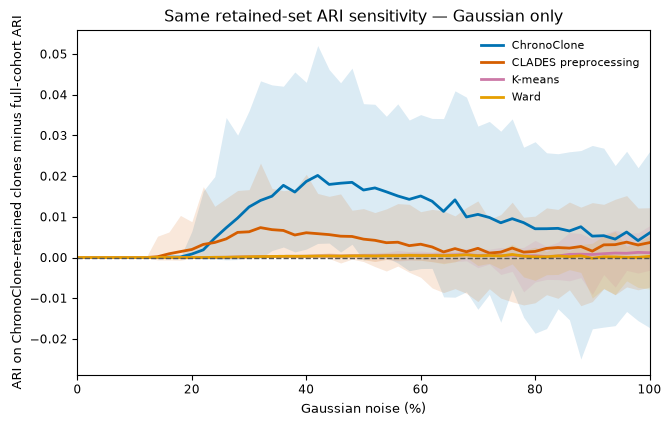

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/manuscript_four_method/gaussian_only_same_retained_ari_sensitivity.svg


In [16]:
# Plot-specific shaping and full construction: Same retained-set ARI sensitivity — Gaussian only
sensitivity_axis = same_retained_plot.loc[same_retained["uniform_pct"].eq(0)].copy()
fig, ax = plt.subplots(figsize=(6.8, 4.35))
for method in METHODS:
    data = sensitivity_axis.loc[sensitivity_axis["method"].eq(method)].sort_values('gaussian_pct')
    x = data['gaussian_pct'].to_numpy(float)
    mean = data["shared_retained_minus_full_ari_mean"].to_numpy(float)
    lower = data["shared_retained_minus_full_ari_q025"].to_numpy(float)
    upper = data["shared_retained_minus_full_ari_q975"].to_numpy(float)
    finite = np.isfinite(mean)
    if finite.any():
        ax.plot(x[finite], mean[finite], color=COLORS[method], linewidth=2.0, label=method)
        band = finite & np.isfinite(lower) & np.isfinite(upper)
        if band.any():
            ax.fill_between(x[band], lower[band], upper[band], color=COLORS[method], alpha=0.14, linewidth=0)
ax.axhline(0, color="#555555", linewidth=1, linestyle="--")
ax.set_xlim(0, 100)
ax.set_xlabel('Gaussian noise (%)')
ax.set_ylabel("ARI on ChronoClone-retained clones minus full-cohort ARI")
ax.set_title('Same retained-set ARI sensitivity — Gaussian only')
handles, labels = ax.get_legend_handles_labels()
if handles:
    ax.legend(handles, labels, frameon=False, fontsize=8)
fig.tight_layout()
output_path = FIGURES / 'gaussian_only_same_retained_ari_sensitivity.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
fig.savefig(output_path.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()
print(output_path)


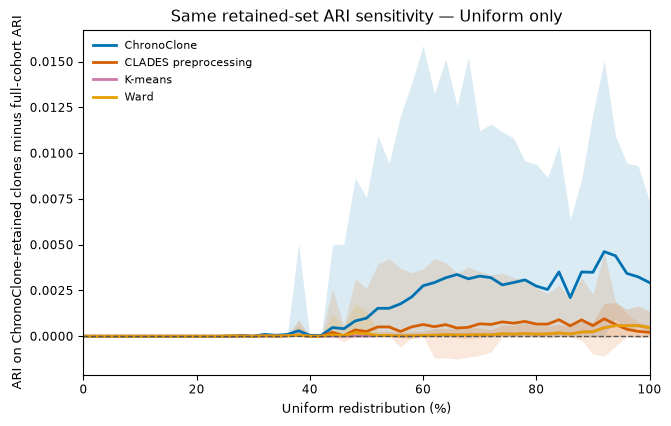

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/manuscript_four_method/uniform_only_same_retained_ari_sensitivity.svg


In [17]:
# Plot-specific shaping and full construction: Same retained-set ARI sensitivity — Uniform only
sensitivity_axis = same_retained_plot.loc[same_retained["gaussian_pct"].eq(0)].copy()
fig, ax = plt.subplots(figsize=(6.8, 4.35))
for method in METHODS:
    data = sensitivity_axis.loc[sensitivity_axis["method"].eq(method)].sort_values('uniform_pct')
    x = data['uniform_pct'].to_numpy(float)
    mean = data["shared_retained_minus_full_ari_mean"].to_numpy(float)
    lower = data["shared_retained_minus_full_ari_q025"].to_numpy(float)
    upper = data["shared_retained_minus_full_ari_q975"].to_numpy(float)
    finite = np.isfinite(mean)
    if finite.any():
        ax.plot(x[finite], mean[finite], color=COLORS[method], linewidth=2.0, label=method)
        band = finite & np.isfinite(lower) & np.isfinite(upper)
        if band.any():
            ax.fill_between(x[band], lower[band], upper[band], color=COLORS[method], alpha=0.14, linewidth=0)
ax.axhline(0, color="#555555", linewidth=1, linestyle="--")
ax.set_xlim(0, 100)
ax.set_xlabel('Uniform redistribution (%)')
ax.set_ylabel("ARI on ChronoClone-retained clones minus full-cohort ARI")
ax.set_title('Same retained-set ARI sensitivity — Uniform only')
handles, labels = ax.get_legend_handles_labels()
if handles:
    ax.legend(handles, labels, frameon=False, fontsize=8)
fig.tight_layout()
output_path = FIGURES / 'uniform_only_same_retained_ari_sensitivity.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
fig.savefig(output_path.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()
print(output_path)


In [18]:
selective_endpoints = pd.concat(
    [
        selective.loc[selective["uniform_pct"].eq(0)].assign(axis="Gaussian only", noise_pct=lambda x: x["gaussian_pct"]),
        selective.loc[selective["gaussian_pct"].eq(0)].assign(axis="Uniform only", noise_pct=lambda x: x["uniform_pct"]),
    ],
    ignore_index=True,
)
selective_columns = [
    "axis", "noise_pct", "postfit_retained_fraction_of_eligible_mean",
    "shared_retained_subset_ari_mean", "postfit_retained_k_mean",
    "postfit_clusters_lost_mean", "n_postfilter_ok", "n_postfilter_all_abstained",
    "n_postfilter_insufficient", "n_postfilter_other",
]
display(selective_endpoints.loc[selective_endpoints["noise_pct"].isin([0, 10, 20, 50, 100]), selective_columns].sort_values(["axis", "noise_pct"]))
failure_totals = completeness_plot.groupby("method", sort=False)[["n_success", "n_method_failure"]].sum().reset_index()
display(failure_totals)
if len(failures_plot):
    display(failures_plot.groupby(["method", "error_type"], as_index=False)["count"].sum())
else:
    display(pd.DataFrame({"status": ["No native method failures among the four plotted methods"]}))


,axis,noise_pct,postfit_retained_fraction_of_eligible_mean,shared_retained_subset_ari_mean,postfit_retained_k_mean,postfit_clusters_lost_mean,n_postfilter_ok,n_postfilter_all_abstained,n_postfilter_insufficient,n_postfilter_other
0,Gaussian only,0,1.000000,1.000000,12.00,0.0,100,0,0,0
5,Gaussian only,10,1.000000,0.999954,12.00,0.0,100,0,0,0
10,Gaussian only,20,0.998027,0.986881,12.00,0.0,100,0,0,0
25,Gaussian only,50,0.972944,0.471111,13.76,0.0,100,0,0,0
50,Gaussian only,100,0.956422,0.306951,13.58,0.0,100,0,0,0
51,Uniform only,0,1.000000,1.000000,12.00,0.0,100,0,0,0
56,Uniform only,10,1.000000,1.000000,12.00,0.0,100,0,0,0
61,Uniform only,20,1.000000,0.999947,12.00,0.0,100,0,0,0
76,Uniform only,50,0.999574,0.942997,11.97,0.0,100,0,0,0
101,Uniform only,100,0.991315,0.175328,21.74,0.0,100,0,0,0


,method,n_success,n_method_failure
0,ChronoClone,260100,0
1,CLADES preprocessing,260100,0
2,K-means,260100,0
3,Ward,260100,0


,status
0,No native method failures among the four plott...


## Scope limits

- CLADES denotes its published mouse preprocessing partition, not its
  NeuralODE/Gillespie stages.
- K-means and Ward use a predeclared truth-blind silhouette K grid.
- The four plotted methods retain their native feature/selection rules, so the
  result is not an isolated comparison of clustering machinery.
- The deterministic 12-program generator is a technical-noise stress test,
  not evidence of real-data biological generality.
- The abundance-only Cyclone core is deliberately excluded from every plot in
  this copy because the separate executed applicability audit shows that the
  state-composition benchmark does not provide it with an identifiable target.
  Its completed rows remain preserved in the source aggregate and are not
  recoded as accuracy zero.

In [19]:
expected_figures = {
    "gaussian_only_mean_ari_by_method.svg",
    "uniform_only_mean_ari_by_method.svg",
    "chronoclone_mean_ari_heatmap.svg",
    "clades_preprocessing_mean_ari_heatmap.svg",
    "kmeans_mean_ari_heatmap.svg",
    "ward_mean_ari_heatmap.svg",
    "gaussian_only_method_success_fraction.svg",
    "uniform_only_method_success_fraction.svg",
    "isolated_axes_eligible_clone_fraction.svg",
    "gaussian_only_recovered_k.svg",
    "uniform_only_recovered_k.svg",
    "chronoclone_isolated_axes_postfit_coverage.svg",
    "gaussian_only_same_retained_ari_sensitivity.svg",
    "uniform_only_same_retained_ari_sensitivity.svg",
}
svg_rows = []
for name in sorted(expected_figures):
    path = FIGURES / name
    root = ET.parse(path).getroot()
    tags = [element.tag.rsplit("}", 1)[-1] for element in root.iter()]
    svg_text = path.read_text(encoding="utf-8")
    svg_rows.append({
        "figure": name,
        "exists": path.is_file(),
        "has_live_text": "text" in tags,
        "has_embedded_raster": "image" in tags,
        "contains_excluded_method_label": "Cyclone" in svg_text,
        "sha256": sha256(path),
        "bytes": path.stat().st_size,
    })
svg_validation = pd.DataFrame(svg_rows)
assert len(svg_validation) == 14
assert svg_validation["exists"].all()
assert svg_validation["has_live_text"].all()
assert not svg_validation["has_embedded_raster"].any()
assert not svg_validation["contains_excluded_method_label"].any()
display(svg_validation)

,figure,exists,has_live_text,has_embedded_raster,contains_excluded_method_label,sha256,bytes
0,chronoclone_isolated_axes_postfit_coverage.svg,True,True,False,False,3697acb8da0e44459a3d4d59fce2b9d55ccb9fa6e47c13...,19886
1,chronoclone_mean_ari_heatmap.svg,True,True,False,False,cf860719734b7df18c6af26f99c8aec2a6e21d8a32d432...,560601
2,clades_preprocessing_mean_ari_heatmap.svg,True,True,False,False,2336afd289a59104a0dbc14e5fe6a78de99fb000d3b18d...,560610
3,gaussian_only_mean_ari_by_method.svg,True,True,False,False,d4eaf4095ab8d4701b37a43cb3d2141533f19b77c51fc0...,29097
4,gaussian_only_method_success_fraction.svg,True,True,False,False,b4cfa8ede0ce5b1d9709348c8fd16d5c6108f6b7be09d9...,12183
5,gaussian_only_recovered_k.svg,True,True,False,False,6a51256d2b613febe323d1a84990f27d426f91a6e00dbe...,30774
6,gaussian_only_same_retained_ari_sensitivity.svg,True,True,False,False,2c6969af8962f8d1362535eef356e92870f7e2bf762f23...,31062
7,isolated_axes_eligible_clone_fraction.svg,True,True,False,False,f74797ebb998a1f54a8e54a8928016db951cb558d16cd9...,19900
8,kmeans_mean_ari_heatmap.svg,True,True,False,False,55e498b8283214ec9bde8d2f6b01e3aa100eb641bfa409...,560593
9,uniform_only_mean_ari_by_method.svg,True,True,False,False,66be1f4c415e110986afca42d0e8396bf9f253fb972c24...,29169
